# Modelado Housing: comparación de modelos y elección del modelo final

Parte de los conjuntos que deja `Build_Model_Housing.ipynb` en `data/processed/` y compara los cuatro modelos preparados ahí: Ridge, Lasso, Random Forest y XGBoost. Son las tres familias de algoritmos que preseleccionó la EP1: regresión lineal regularizada, bosques aleatorios y gradient boosting.

- Sección 1: carga de datos.
- Sección 2: criterio de salida y regla de elección, fijados antes de ver resultados.
- Sección 3: modelos y justificación de sus parámetros iniciales.
- Sección 4: validación cruzada sobre train, con el error en train y en validación de cada fold.
- Sección 5: evaluación en test y cumplimiento de los KPI.
- Sección 6: error por condición de venta y por tramo de precio.
- Sección 7: elección del modelo.
- Sección 8: qué significa el modelo elegido para la tasación.
- Sección 9: conclusiones.

La búsqueda de hiperparámetros queda fuera del alcance de esta entrega: los modelos usan parámetros iniciales fijos, justificados en la sección 3.

Entorno: igual que el notebook de preparación, corre en Google Colab y en local. Los números citados en el texto corresponden a una ejecución con las versiones de Colab (Python 3.13, numpy 2.1.3, pandas 2.2.3, scikit-learn 1.6.1 y xgboost 3.4.1). Con otras versiones, los resultados de Random Forest y XGBoost pueden cambiar en algunos cientos de dólares.

**Importación de librerías**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

# Reproducibilidad
RANDOM_STATE = 42

# Gráficos: una sola serie por gráfico, en un solo color
COLOR = '#2a78d6'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True})

**Ejecución en Colab o en local**

Igual que en `Build_Model_Housing.ipynb`: en Colab, la celda siguiente clona la rama `RAMA` del repositorio en `/content` y se ubica en `notebooks/`, para que las rutas `../data/` funcionen igual que en local. En local no clona nada. En los dos casos imprime las versiones de las librerías.

In [2]:
import os, sys, shutil, subprocess
import sklearn, xgboost

RAMA = 'Nicolas'   # rama que se clona en Colab; cambiar a 'main' cuando se fusione
REPO = 'https://github.com/javisagredo-dev/Housing_Prices_ML_P2.git'

if 'google.colab' in sys.modules:
    RAIZ = '/content/Housing_Prices_ML_P2'
    # /content es temporal: se clona de nuevo en cada ejecución para usar siempre la última versión de RAMA
    os.chdir('/content')
    shutil.rmtree(RAIZ, ignore_errors=True)
    subprocess.run(['git', 'clone', '--depth', '1', '-b', RAMA, REPO, RAIZ], check=True)
    os.chdir(f'{RAIZ}/notebooks')

print('Carpeta de trabajo:', os.getcwd())
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__}")

Carpeta de trabajo: /content/Housing_Prices_ML_P2/notebooks
Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | xgboost 3.4.1


## 1. Carga de datos

Cada modelo usa el conjunto que se preparó para él: `df_ridge_lasso` para Ridge y Lasso (138 columnas, escaladas) y `df_random_forest` y `df_xgboost` para los árboles (158 columnas). Cada conjunto tiene tres partes: train (2.314 casas), test (582 casas) y test con venta normal impuesta (las mismas 582 casas; ver la sección 11.1 del notebook de preparación). El escalado y el target encoding se ajustaron solo con train, así que el test no influyó en la preparación.

Los CSV no traen el nombre de la columna del índice, así que se cargan con `index_col=0`. La celda verifica que los tres conjuntos tengan las mismas casas y el mismo `SalePrice`, sin valores faltantes.

In [3]:
RUTA_DATOS = '../data/processed/'
CONJUNTOS = ['ridge_lasso', 'random_forest', 'xgboost']
PARTES = ['train', 'test', 'test_venta_normal']


def cargar(conjunto, parte):
    # Los CSV traen el id de ames_clean.csv como primera columna (sin nombre) y SalePrice al final
    df = pd.read_csv(f'{RUTA_DATOS}df_{conjunto}_{parte}.csv', index_col=0)
    df.index.name = 'id'
    return df.drop(columns='SalePrice'), df['SalePrice']


datos = {c: {p: cargar(c, p) for p in PARTES} for c in CONJUNTOS}
segmentos = pd.read_csv(f'{RUTA_DATOS}segmentos.csv', index_col='id')

# Los tres conjuntos tienen las mismas casas y el mismo SalePrice
y_train = datos['ridge_lasso']['train'][1]
y_test = datos['ridge_lasso']['test'][1]
for c in CONJUNTOS:
    for p in PARTES:
        X, y = datos[c][p]
        assert y.equals(y_train if p == 'train' else y_test), (c, p)
        assert X.notnull().all().all(), (c, p)
    assert list(datos[c]['train'][0].columns) == list(datos[c]['test'][0].columns)

seg_test = segmentos.loc[y_test.index]
assert seg_test['Conjunto'].eq('test').all() and segmentos.loc[y_train.index, 'Conjunto'].eq('train').all()

print(pd.DataFrame({c: {p: f"{datos[c][p][0].shape[0]} casas x {datos[c][p][0].shape[1]} columnas" for p in PARTES}
                    for c in CONJUNTOS}).T.to_string())

                                   train                      test         test_venta_normal
ridge_lasso    2314 casas x 138 columnas  582 casas x 138 columnas  582 casas x 138 columnas
random_forest  2314 casas x 158 columnas  582 casas x 158 columnas  582 casas x 158 columnas
xgboost        2314 casas x 158 columnas  582 casas x 158 columnas  582 casas x 158 columnas


## 2. Criterio de salida y regla de elección

Se fijan antes de entrenar y no se cambian después de ver los resultados.

El criterio de salida es el de la EP1 (Informe, sección 3): un modelo es apto solo si cumple los seis KPI a la vez en el test.

| KPI | Umbral | Qué controla |
|---|---|---|
| R² | ≥ 0,85 | Qué parte de la variación de los precios explica el modelo |
| RMSE | ≤ 30.000 USD | Error en dólares, castigando más los errores grandes |
| MAE | ≤ 20.000 USD | Error promedio en dólares |
| MAPE | ≤ 12 % | Error relativo al precio de cada casa |
| Brecha de R² entre train y test | ≤ 5 puntos | Sobreajuste: que el modelo no rinda mucho mejor en las casas que ya vio |
| Brecha de MAPE entre barrios | ≤ 8 puntos | Equidad: diferencia de MAPE entre el barrio mejor y el peor predicho |

Cómo se calcula cada uno:

- La brecha de R² compara el R² del modelo entrenado con todo train, medido sobre el mismo train, con su R² en test.
- La brecha entre barrios considera solo los barrios con al menos 10 casas en test, el mismo corte que usó la auditoría de equidad de la EP1. Con menos casas, el MAPE de un barrio depende de dos o tres ventas.
- Los KPI se evalúan sobre el test real. El test con venta normal impuesta se informa como segundo escenario, porque es el más parecido al uso real (al tasar no se sabe cómo se cerrará la venta), pero no decide.

Regla de elección:

1. Solo compiten los modelos que cumplen los seis KPI en el test real.
2. Entre ellos se prefiere el de menor RMSE en validación cruzada, la métrica principal de la EP1 (sección 9). Se usa la validación y no el test para que el test quede como una medición independiente y no como un criterio para elegir.
3. Si otro modelo que cumple queda a menos de 1 punto de R² de validación, se elige el más interpretable (EP1, sección 8.4): primero los lineales y, entre ellos, el que usa menos variables. Un valor que depende de menos variables es más fácil de justificar ante un cliente.
4. Si ningún modelo cumple, no se bajan los umbrales: según la EP1, se vuelve a una fase anterior.

In [4]:
# Criterio de salida de la EP1 (Informe, sección 3.1). Se fija antes de evaluar.
KPI = pd.DataFrame([
    ('R²', '≥', 0.85),
    ('RMSE', '≤', 30_000),
    ('MAE', '≤', 20_000),
    ('MAPE %', '≤', 12),
    ('Brecha R² train-test (pts)', '≤', 5),
    ('Brecha MAPE barrios (pts)', '≤', 8),
], columns=['KPI', 'Sentido', 'Umbral']).set_index('KPI')

MIN_CASAS_BARRIO = 10   # barrios con menos casas en test no entran a la brecha de equidad (mismo corte que la EP1)
TOLERANCIA_R2 = 0.01    # bajo esta diferencia de R² se prefiere el modelo más interpretable (EP1, sección 8.4)


def cumple(valor, kpi):
    sentido, umbral = KPI.loc[kpi]
    return valor >= umbral if sentido == '≥' else valor <= umbral


with pd.option_context('display.float_format', '{:g}'.format):
    print(KPI.to_string())

                           Sentido  Umbral
KPI                                       
R²                               ≥    0.85
RMSE                             ≤   30000
MAE                              ≤   20000
MAPE %                           ≤      12
Brecha R² train-test (pts)       ≤       5
Brecha MAPE barrios (pts)        ≤       8


## 3. Modelos y parámetros iniciales

Los cuatro modelos se entrenan sobre `log1p(SalePrice)` con `TransformedTargetRegressor`, que devuelve las predicciones en dólares. La EP1 (sección 10.7) mostró que entrenar en escala logarítmica reduce la brecha de error entre barrios: el modelo minimiza el error relativo en vez del error en dólares y deja de favorecer a las casas caras.

No hay búsqueda de hiperparámetros. Los parámetros son los mismos que usó `Build_Model_Housing.ipynb` para tomar las decisiones de preparación, así que los resultados de los dos notebooks se pueden comparar.

| Modelo | Parámetro | Valor | Justificación |
|---|---|---|---|
| Ridge | `alphas` de `RidgeCV` | 30 valores entre 0,01 y 1.000, en escala logarítmica | Con 138 columnas, varias correlacionadas entre sí, un modelo lineal sin penalización infla los coeficientes. La penalización (alpha) es parte del ajuste del modelo: `RidgeCV` la elige con validación cruzada interna (leave-one-out) usando solo train. El rango va desde casi sin penalización hasta una penalización fuerte. Si el alpha elegido quedara en un extremo, el rango sería corto; se revisa en la sección 5. |
| Lasso | `alphas` de `LassoCV` | 30 valores entre 0,00001 y 0,1 | Mismo criterio. El rango es más bajo que el de Ridge porque Lasso mide la penalización en otra escala: con alpha = 0,1 deja solo 5 de los 138 coeficientes distintos de 0. `LassoCV` elige alpha con 5 folds dentro de train. |
| Lasso | `max_iter` | 50.000 | Número máximo de iteraciones del algoritmo de ajuste. Es un margen para que converja con todas las alphas del rango; con estos datos también converge con el valor por defecto (1.000), así que no cambia el resultado. |
| Random Forest | `n_estimators` | 300 | Agregar árboles no produce sobreajuste: la predicción se estabiliza a medida que crece el número de árboles y solo aumenta el tiempo de cómputo (Breiman, 2001). |
| Random Forest | resto | valores por defecto de scikit-learn | Los árboles crecen sin límite de profundidad (`max_depth=None`, `min_samples_leaf=1`) y cada uno se entrena con una muestra con reposición de train. En cada corte se consideran todas las variables (`max_features=1.0`, el valor por defecto en regresión). Cada árbol sobreajusta por separado y el promedio de 300 árboles reduce esa variación; la consecuencia es que el bosque casi memoriza train, lo que se mide con la brecha de R². |
| XGBoost | `n_estimators` y `learning_rate` | 500 y 0,05 | En boosting cada árbol corrige parte del error de los anteriores. Con una tasa de aprendizaje baja cada árbol corrige menos y se necesitan más árboles; a cambio, el modelo suele generalizar mejor que con una tasa alta y pocos árboles (Friedman, 2001). Es una combinación de partida habitual frente a la tasa por defecto de 0,3. |
| XGBoost | `tree_method` | `hist` | Agrupa los valores de cada variable en intervalos para buscar los cortes. Es el método por defecto desde XGBoost 2.0 y el más rápido. |
| XGBoost | resto | valores por defecto | Profundidad máxima de 6 por árbol, sin submuestreo de filas ni de columnas. |
| Todos | `random_state` | 42 | Resultados reproducibles. |

In [5]:
def con_log(regresor):
    # Entrena sobre log1p(SalePrice) y devuelve las predicciones en dólares
    return TransformedTargetRegressor(regressor=regresor, func=np.log1p, inverse_func=np.expm1)


# Cada modelo con el conjunto de datos que preparó Build_Model_Housing.ipynb para él
modelos = {
    'Ridge': ('ridge_lasso', con_log(RidgeCV(alphas=np.logspace(-2, 3, 30)))),
    'Lasso': ('ridge_lasso', con_log(LassoCV(alphas=np.logspace(-5, -1, 30), max_iter=50000,
                                             random_state=RANDOM_STATE))),
    'Random Forest': ('random_forest', con_log(RandomForestRegressor(n_estimators=300, n_jobs=-1,
                                                                     random_state=RANDOM_STATE))),
    'XGBoost': ('xgboost', con_log(XGBRegressor(tree_method='hist', n_estimators=500, learning_rate=0.05,
                                                random_state=RANDOM_STATE))),
}

## 4. Validación cruzada sobre train

Se usan 5 folds con el mismo `KFold(n_splits=5, shuffle=True, random_state=42)` del notebook de preparación. En cada fold el modelo se entrena con 4/5 de train y se mide en el quinto restante (validación) y en las casas con que se entrenó (train). La diferencia entre los dos es la primera señal de sobreajuste. El test no participa.

Los CSV ya vienen escalados y con el target encoding ajustado sobre todo train, así que en cada fold la preparación vio también las casas de validación. El efecto es pequeño: los RMSE de esta tabla quedan a menos de 200 USD de los que obtuvo el notebook de preparación con los pipelines completos, que ajustan la preparación de nuevo en cada fold. El test no tiene este problema, porque la preparación se ajustó solo con train.

In [6]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metricas = {'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error',
            'mape': 'neg_mean_absolute_percentage_error', 'r2': 'r2'}

filas = []
for nombre, (conjunto, modelo) in modelos.items():
    X_tr = datos[conjunto]['train'][0]
    res = cross_validate(clone(modelo), X_tr, y_train, cv=cv, scoring=metricas, return_train_score=True)
    filas.append({
        'Modelo': nombre,
        'RMSE train': -res['train_rmse'].mean(),
        'RMSE val': -res['test_rmse'].mean(),
        'Desv. RMSE val': res['test_rmse'].std(),
        'MAE val': -res['test_mae'].mean(),
        'MAPE % val': -res['test_mape'].mean() * 100,
        'R² train': res['train_r2'].mean(),
        'R² val': res['test_r2'].mean(),
        'Brecha R² (pts)': (res['train_r2'].mean() - res['test_r2'].mean()) * 100,
    })

resultados_cv = pd.DataFrame(filas).set_index('Modelo')
print(resultados_cv.round({'RMSE train': 0, 'RMSE val': 0, 'Desv. RMSE val': 0, 'MAE val': 0,
                           'MAPE % val': 2, 'R² train': 3, 'R² val': 3, 'Brecha R² (pts)': 1}).to_string())

               RMSE train  RMSE val  Desv. RMSE val  MAE val  MAPE % val  R² train  R² val  Brecha R² (pts)
Modelo                                                                                                     
Ridge             18831.0   20152.0          1018.0  13742.0        8.07     0.940   0.930              1.0
Lasso             18919.0   20206.0          1077.0  13766.0        8.08     0.939   0.930              0.9
Random Forest      9451.0   25136.0          2518.0  15839.0        9.25     0.985   0.891              9.3
XGBoost            3598.0   22529.0          1554.0  14328.0        8.40     0.998   0.913              8.5


- Ridge y Lasso tienen casi el mismo error (20.152 y 20.206 USD de RMSE) y una brecha de R² de 1 punto entre train y validación: rinden casi igual en las casas que vieron y en las nuevas.
- Random Forest y XGBoost casi memorizan train (R² de 0,985 y 0,998; RMSE de 9.451 y 3.598 USD) y en validación quedan peor que los lineales (25.136 y 22.529 USD). Sus brechas de 9,3 y 8,5 puntos superan el máximo de 5 de la EP1, así que es probable que tampoco cumplan ese KPI en test. Es la consecuencia de usar árboles sin límite de profundidad (sección 3). Limitar la profundidad o el tamaño mínimo de las hojas es búsqueda de hiperparámetros y queda fuera de esta entrega.
- La variación entre folds también es menor en los lineales: la desviación del RMSE es de unos 1.000 USD, frente a 1.554 en XGBoost y 2.518 en Random Forest. Su error depende menos de qué casas les tocan.

## 5. Evaluación en test

Cada modelo se entrena con las 2.314 casas de train y se mide sobre las 582 de test, que no se usaron en ningún paso anterior. Se reportan los dos escenarios: el test real y el test con venta normal impuesta.

In [7]:
def mape_por_barrio(real, pred):
    ape = (real - pred).abs() / real * 100
    por_barrio = ape.groupby(seg_test['Neighborhood']).agg(['size', 'mean'])
    return por_barrio.loc[por_barrio['size'] >= MIN_CASAS_BARRIO, 'mean'].sort_values()


def calcular_kpis(real, pred, r2_train):
    barrios = mape_por_barrio(real, pred)
    r2 = r2_score(real, pred)
    return {'R²': r2,
            'RMSE': root_mean_squared_error(real, pred),
            'MAE': mean_absolute_error(real, pred),
            'MAPE %': mean_absolute_percentage_error(real, pred) * 100,
            'Brecha R² train-test (pts)': (r2_train - r2) * 100,
            'Brecha MAPE barrios (pts)': barrios.max() - barrios.min()}


ESCENARIOS = {'Test real': 'test', 'Venta normal impuesta': 'test_venta_normal'}
ajustados, predicciones, r2_train, kpis = {}, {}, {}, {}
for nombre, (conjunto, modelo) in modelos.items():
    X_tr = datos[conjunto]['train'][0]
    ajustados[nombre] = clone(modelo).fit(X_tr, y_train)
    r2_train[nombre] = r2_score(y_train, ajustados[nombre].predict(X_tr))
    for escenario, parte in ESCENARIOS.items():
        pred = pd.Series(ajustados[nombre].predict(datos[conjunto][parte][0]), index=y_test.index)
        predicciones[(escenario, nombre)] = pred
        kpis[(escenario, nombre)] = calcular_kpis(y_test, pred, r2_train[nombre])

kpis = pd.DataFrame(kpis).T
kpis.index.names = ['Escenario', 'Modelo']
cumplimiento = pd.DataFrame({k: kpis[k].apply(cumple, kpi=k) for k in KPI.index})
cumplimiento['Cumple los seis'] = cumplimiento.all(axis=1)

formato = {'R²': 3, 'RMSE': 0, 'MAE': 0, 'MAPE %': 2, 'Brecha R² train-test (pts)': 1, 'Brecha MAPE barrios (pts)': 1}
for escenario in ESCENARIOS:
    print(f"=== {escenario} ({len(y_test)} casas) ===")
    print(kpis.loc[escenario].round(formato).to_string())
    print()
    print(cumplimiento.loc[escenario].replace({True: 'Sí', False: 'No'}).to_string())
    print()

=== Test real (582 casas) ===
                  R²     RMSE      MAE  MAPE %  Brecha R² train-test (pts)  Brecha MAPE barrios (pts)
Modelo                                                                                               
Ridge          0.948  19126.0  12373.0    6.75                        -0.9                        6.1
Lasso          0.948  19241.0  12407.0    6.77                        -0.9                        6.1
Random Forest  0.924  23219.0  14359.0    7.94                         6.1                       10.0
XGBoost        0.934  21660.0  13579.0    7.39                         6.3                        7.7

               R² RMSE MAE MAPE % Brecha R² train-test (pts) Brecha MAPE barrios (pts) Cumple los seis
Modelo                                                                                                
Ridge          Sí   Sí  Sí     Sí                         Sí                        Sí              Sí
Lasso          Sí   Sí  Sí     Sí               

In [8]:
# Alpha elegido por RidgeCV y LassoCV dentro de train (sección 3): no debe quedar en un extremo del rango
for nombre in ['Ridge', 'Lasso']:
    regresor = ajustados[nombre].regressor_
    rango = getattr(regresor, 'alphas_', regresor.alphas)
    print(f"{nombre}: alpha = {regresor.alpha_:.3g} (rango {min(rango):g} a {max(rango):g}) | "
          f"coeficientes distintos de 0: {(regresor.coef_ != 0).sum()} de {len(regresor.coef_)}")

columnas = datos['ridge_lasso']['train'][0].columns
print("Columnas con coeficiente 0 en Lasso:", list(columnas[ajustados['Lasso'].regressor_.coef_ == 0]))

Ridge: alpha = 8.53 (rango 0.01 a 1000) | coeficientes distintos de 0: 138 de 138
Lasso: alpha = 0.000174 (rango 1e-05 a 0.1) | coeficientes distintos de 0: 105 de 138
Columnas con coeficiente 0 en Lasso: ['BsmtFin Type 2', 'MS SubClass_180', 'MS SubClass_45', 'MS SubClass_50', 'MS SubClass_75', 'MS SubClass_80', 'MS SubClass_infrequent_sklearn', 'Land Contour_Lvl', 'Bldg Type_2fmCon', 'House Style_SLvl', 'House Style_infrequent_sklearn', 'Roof Style_Gable', 'Roof Style_Gambrel', 'Roof Matl_Tar&Grv', 'Roof Matl_infrequent_sklearn', 'Mas Vnr Type_BrkFace', 'Mas Vnr Type_infrequent_sklearn', 'Foundation_Slab', 'Foundation_infrequent_sklearn', 'Electrical_FuseF', 'Electrical_infrequent_sklearn', 'Garage Type_Basment', 'Garage Type_BuiltIn', 'Misc Feature_Shed', 'Misc Feature_infrequent_sklearn', 'Sale Type_CWD', 'Sale Type_ConLD', 'Sale Type_infrequent_sklearn', 'Condition 1_RRAe', 'Condition 1_RRAn', 'Condition 1_infrequent_sklearn', 'Condition 2_Norm', 'Tiene_Piscina']


In [9]:
# Casas a las que el test con venta normal les cambia la condición o el tipo de venta
cambian = (datos['ridge_lasso']['test'][0] != datos['ridge_lasso']['test_venta_normal'][0]).any(axis=1)
print(f"Casas que cambian: {cambian.sum()} {seg_test.loc[cambian, 'Sale Condition'].value_counts().to_dict()}")
for nombre in modelos:
    texto = []
    for escenario in ESCENARIOS:
        pred = predicciones[(escenario, nombre)][cambian]
        error = (pred - y_test[cambian]) / y_test[cambian] * 100
        texto.append(f"{escenario}: MAPE {error.abs().mean():4.1f} %, error con signo {error.mean():+.1f} %")
    print(f"{nombre:14s} " + ' | '.join(texto))

Casas que cambian: 64 {'Abnorml': 33, 'Normal': 20, 'Family': 5, 'Alloca': 4, 'AdjLand': 2}
Ridge          Test real: MAPE  9.8 %, error con signo +0.4 % | Venta normal impuesta: MAPE 11.2 %, error con signo +5.7 %
Lasso          Test real: MAPE  9.8 %, error con signo +0.5 % | Venta normal impuesta: MAPE 11.2 %, error con signo +5.8 %
Random Forest  Test real: MAPE 13.8 %, error con signo +4.4 % | Venta normal impuesta: MAPE 14.7 %, error con signo +5.8 %
XGBoost        Test real: MAPE 11.5 %, error con signo +0.6 % | Venta normal impuesta: MAPE 12.4 %, error con signo +4.9 %


- Ridge y Lasso cumplen los seis KPI en los dos escenarios, con margen en todos. En el test real, Lasso tiene un R² de 0,948, un RMSE de 19.241 USD, un MAE de 12.407 USD y un MAPE de 6,77 %. Ridge queda prácticamente igual (115 USD menos de RMSE).
- Random Forest y XGBoost cumplen los cuatro KPI de error, pero no el de sobreajuste: su brecha de R² entre train y test es de 6,1 y 6,3 puntos. Random Forest tampoco cumple el de equidad (10,0 puntos entre barrios). XGBoost lo cumple en el test real (7,7) pero no con la venta normal impuesta (8,9).
- En los lineales la brecha es negativa (−0,9 puntos): rinden algo mejor en test que en train. Su RMSE de test queda unos 1.000 USD bajo el de validación cruzada, una diferencia del mismo orden que la variación entre folds. Estas 582 casas resultaron algo más fáciles de predecir que el promedio. Por la misma razón, las brechas de los árboles en test (6,1 y 6,3) son menores que en validación (9,3 y 8,5), pero siguen sobre el máximo.
- El alpha que eligieron `RidgeCV` (8,53) y `LassoCV` (0,000174) queda dentro del rango en los dos casos, lejos de los extremos. Lasso deja en 0 los coeficientes de 33 columnas.
- Con la venta normal impuesta, el MAPE de Lasso sube poco en total (de 6,77 % a 6,93 %). El cambio se concentra en las 64 casas a las que se les cambió la condición o el tipo de venta: ahí el MAPE pasa de 9,8 % a 11,2 % y el modelo pasa a sobreestimar en promedio un 5,8 %. Es el comportamiento buscado: con la venta normal impuesta, el modelo estima el valor de mercado, y la mayoría de esas casas son ventas anómalas (33) o entre familiares (5), que suelen cerrarse bajo el valor de mercado: según la documentación del dataset, `Abnorml` agrupa remates, ventas cortas e intercambios.

In [10]:
# Barrios con mayor y menor MAPE en el test real (barrios con al menos MIN_CASAS_BARRIO casas)
n_barrios = (seg_test['Neighborhood'].value_counts() >= MIN_CASAS_BARRIO).sum()
print(f"Barrios que entran a la brecha: {n_barrios} de {seg_test['Neighborhood'].nunique()}")
for nombre in modelos:
    barrios = mape_por_barrio(y_test, predicciones[('Test real', nombre)])
    print(f"{nombre:14s} peor: {barrios.index[-1]} {barrios.iloc[-1]:.1f} % | mejor: {barrios.index[0]} {barrios.iloc[0]:.1f} %")

Barrios que entran a la brecha: 17 de 25
Ridge          peor: ClearCr 10.1 % | mejor: CollgCr 4.1 %
Lasso          peor: ClearCr 10.3 % | mejor: CollgCr 4.1 %
Random Forest  peor: IDOTRR 14.8 % | mejor: SawyerW 4.9 %
XGBoost        peor: SWISU 11.9 % | mejor: SawyerW 4.3 %


De los 25 barrios del test, 17 tienen al menos 10 casas y entran a la brecha de equidad. En los lineales, el barrio peor predicho es `ClearCr` (10,3 % de MAPE en Lasso) y el mejor `CollgCr` (4,1 %). En Random Forest el peor es `IDOTRR` (14,8 %), uno de los barrios con más ventas anómalas y también el peor en la auditoría de equidad de la EP1 con el modelo entrenado en dólares.

## 6. Error por segmento

El error promedio no muestra dónde se equivoca el modelo. Esta sección desglosa el MAPE del test real por condición de venta y por tramo de precio, para los cuatro modelos.

In [11]:
real = y_test
ape = pd.DataFrame({m: (real - predicciones[('Test real', m)]).abs() / real * 100 for m in modelos})
sesgo = pd.DataFrame({m: (predicciones[('Test real', m)] - real) / real * 100 for m in modelos})   # > 0: sobreestima

condicion = seg_test['Sale Condition']
tabla = ape.groupby(condicion).mean().round(1)
tabla.insert(0, 'Casas', condicion.value_counts())
print("=== MAPE % por condición de venta (test real) ===")
print(tabla.sort_values('Casas', ascending=False).to_string())

=== MAPE % por condición de venta (test real) ===
                Casas  Ridge  Lasso  Random Forest  XGBoost
Sale Condition                                             
Normal            483    6.3    6.3            7.2      6.8
Partial            55    7.7    7.6            8.2      8.3
Abnorml            33   11.2   11.2           16.4     13.2
Family              5   15.4   15.5           19.0     19.1
Alloca              4    4.5    3.3            8.7      4.4
AdjLand             2    9.1   13.5            6.9      7.4


Los cuatro modelos se equivocan más en las ventas `Abnorml` (11,2 % en Lasso, 16,4 % en Random Forest) y `Family` (15,5 % en Lasso) que en las `Normal` (6,3 % en Lasso). Como la condición de venta no se conoce antes de vender, esas casas no se pueden separar al tasar: es un límite del modelo. `Family`, `Alloca` y `AdjLand` tienen 5 casas o menos en test, así que sus porcentajes cambian mucho con una sola casa.

In [12]:
tramos = pd.qcut(real, 4)
tramos = tramos.cat.rename_categories([f"{i.left:,.0f} a {i.right:,.0f}".replace(',', '.') for i in tramos.cat.categories])

tabla_mape = ape.groupby(tramos, observed=True).mean().round(1)
tabla_sesgo = sesgo.groupby(tramos, observed=True).mean().round(1)
tabla_mape.index.name = tabla_sesgo.index.name = 'Precio real (USD)'
print("=== MAPE % por tramo de precio (cuartiles del test real) ===")
print(tabla_mape.to_string())
print()
print("=== Error con signo % por tramo (positivo: el modelo sobreestima) ===")
print(tabla_sesgo.to_string())

=== MAPE % por tramo de precio (cuartiles del test real) ===
                   Ridge  Lasso  Random Forest  XGBoost
Precio real (USD)                                      
46.500 a 130.625     8.7    8.8           11.6     10.3
130.625 a 160.000    5.8    5.8            5.6      5.7
160.000 a 215.000    5.9    5.8            6.3      5.7
215.000 a 611.657    6.6    6.6            8.3      7.9

=== Error con signo % por tramo (positivo: el modelo sobreestima) ===
                   Ridge  Lasso  Random Forest  XGBoost
Precio real (USD)                                      
46.500 a 130.625     3.3    3.4            6.7      4.6
130.625 a 160.000    0.3    0.2           -0.5      0.1
160.000 a 215.000    1.1    1.2           -0.7     -0.9
215.000 a 611.657   -2.6   -2.5           -4.9     -3.7


- El cuartil más barato (hasta 130.625 USD) es el de mayor error en los cuatro modelos: 8,8 % en Lasso y 11,6 % en Random Forest. En los dos tramos del medio el error baja a cerca de 6 %.
- El error con signo muestra que las estimaciones se cargan hacia el centro: los modelos sobreestiman las casas baratas (Lasso, +3,4 %) y subestiman las caras (Lasso, −2,5 %). En Random Forest el efecto es cerca del doble (+6,7 % y −4,9 %). En el segmento bajo, el valor estimado tiende a quedar sobre el precio real, y es justamente donde un error relativo pesa más para el comprador.

## 7. Elección del modelo

Se aplica la regla de la sección 2.

In [13]:
def complejidad(nombre):
    # Menor es más interpretable: primero los lineales, ordenados por cantidad de coeficientes distintos de 0 (columnas en uso)
    regresor = ajustados[nombre].regressor_
    if hasattr(regresor, 'coef_'):
        return (0, int((regresor.coef_ != 0).sum()))
    return (1, datos[modelos[nombre][0]]['train'][0].shape[1])


cumplen = [m for m in modelos if cumplimiento.loc[('Test real', m), 'Cumple los seis']]
print("1. Cumplen los seis KPI en el test real:", cumplen or 'ninguno')

if cumplen:
    mejor = resultados_cv.loc[cumplen, 'RMSE val'].idxmin()
    print(f"2. Menor RMSE de validación entre ellos: {mejor} ({resultados_cv.loc[mejor, 'RMSE val']:,.0f} USD)")
    cercanos = [m for m in cumplen if resultados_cv.loc[m, 'R² val'] >= resultados_cv.loc[mejor, 'R² val'] - TOLERANCIA_R2]
    print(f"3. A menos de {TOLERANCIA_R2 * 100:.0f} punto de R² de validación del mejor:",
          ', '.join(f"{m} ({resultados_cv.loc[m, 'R² val']:.4f})" for m in cercanos))
    for m in cercanos:
        tipo, n = complejidad(m)
        print(f"   {m}: {'lineal' if tipo == 0 else 'árboles'}, {n} columnas en uso")
    elegido = min(cercanos, key=complejidad)
    print(f"Modelo elegido: {elegido}")
else:
    elegido = None
    print("Ningún modelo cumple el criterio de salida: según la EP1 se vuelve a una fase anterior, no se bajan los umbrales.")

1. Cumplen los seis KPI en el test real: ['Ridge', 'Lasso']
2. Menor RMSE de validación entre ellos: Ridge (20,152 USD)
3. A menos de 1 punto de R² de validación del mejor: Ridge (0.9299), Lasso (0.9295)
   Ridge: lineal, 138 columnas en uso
   Lasso: lineal, 105 columnas en uso
Modelo elegido: Lasso


Ridge y Lasso son los únicos que cumplen los seis KPI. Ridge tiene el menor RMSE de validación, pero Lasso queda a 0,04 puntos de R² (0,9295 frente a 0,9299), muy por debajo de la tolerancia de 1 punto, y usa 105 columnas en vez de 138. Las 33 que dejó en 0 son casi todas dummies de variables nominales (tipo de vivienda, techo, fundación y garaje, entre otras), además de `Tiene_Piscina` y `BsmtFin Type 2`. Por la regla de interpretabilidad, el modelo elegido es Lasso.

La diferencia de precisión entre los dos es mucho menor que la variación entre folds: 54 USD de RMSE en validación y 115 USD en test, frente a una desviación de unos 1.000 USD. En la práctica son equivalentes, y Lasso se explica con menos variables.

## 8. Qué significa el modelo para la tasación

El modelo elegido es una regresión Lasso entrenada sobre el logaritmo del precio. Su uso es entregar al perito un valor de partida para una vivienda en zona residencial de Ames, calculado a partir de las características de la casa, junto con el detalle de qué variables movieron ese valor. No reemplaza la tasación: le da un punto de partida trazable y permite revisar los casos en que el perito y el modelo difieren mucho.

Lasso en el test real (582 casas)
  Error medio: 12,407 USD | error mediano: 8,659 USD
  Error porcentual mediano: 5.3 %
  Casas con error menor a  5 %: 47.1 %
  Casas con error menor a 10 %: 77.8 %
  Casas con error menor a 20 %: 96.6 %
  Casas con error mayor a 30 %: 4
  Casas de más de 450.000 USD: 9, subestimadas: 8 (error con signo: [-28.9, -22.7, -15.5, -13.5, -13.0, -12.2, -6.8, -2.9, 2.7])

Casas con error mayor a 30 %:
       Barrio Condición de venta  Precio real  Estimado  Error %
id                                                              
900   Edwards             Normal       103500  143284.0     38.4
1952    NAmes             Family       135000  184386.0     36.6
695   OldTown            Abnorml        66500   95973.0     44.3
108    Sawyer             Normal       130500  177333.0     35.9


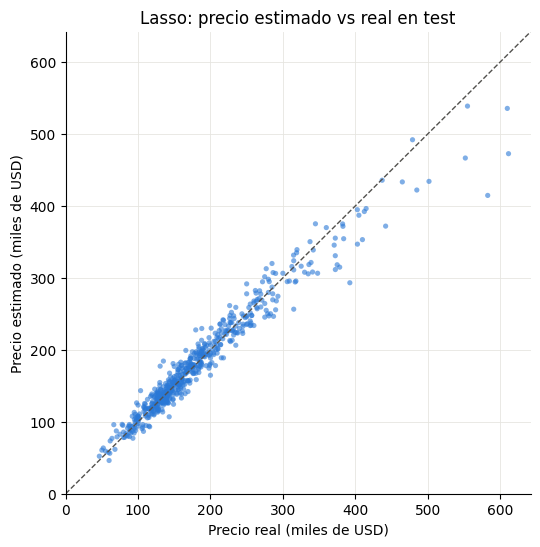

In [14]:
pred = predicciones[('Test real', elegido)]
error_usd = (pred - real).abs()
error_pct = error_usd / real * 100

print(f"{elegido} en el test real ({len(real)} casas)")
print(f"  Error medio: {error_usd.mean():,.0f} USD | error mediano: {error_usd.median():,.0f} USD")
print(f"  Error porcentual mediano: {error_pct.median():.1f} %")
for limite in [5, 10, 20]:
    print(f"  Casas con error menor a {limite:2d} %: {(error_pct < limite).mean() * 100:.1f} %")
print(f"  Casas con error mayor a 30 %: {(error_pct > 30).sum()}")
caras = real > 450_000
print(f"  Casas de más de 450.000 USD: {caras.sum()}, subestimadas: {(pred[caras] < real[caras]).sum()} "
      f"(error con signo: {sorted(((pred[caras] - real[caras]) / real[caras] * 100).round(1).tolist())})")
print()
print("Casas con error mayor a 30 %:")
print(pd.DataFrame({'Barrio': seg_test['Neighborhood'], 'Condición de venta': seg_test['Sale Condition'],
                    'Precio real': real, 'Estimado': pred.round(0), 'Error %': error_pct.round(1)})
      [error_pct > 30].to_string())

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(real / 1000, pred / 1000, s=14, color=COLOR, alpha=0.6, edgecolors='none')
limites = [0, max(real.max(), pred.max()) / 1000 * 1.05]
ax.plot(limites, limites, color='#52514e', linewidth=1, linestyle='--')
ax.set(xlim=limites, ylim=limites, xlabel='Precio real (miles de USD)', ylabel='Precio estimado (miles de USD)',
       title=f'{elegido}: precio estimado vs real en test')
plt.show()

- En la mitad de las casas de test el error es menor a 8.659 USD (5,3 % del precio). El error promedio es mayor, 12.407 USD, porque unas pocas casas tienen errores grandes.
- El 77,8 % de las casas queda con un error menor a 10 % y el 96,6 % con uno menor a 20 %. Solo 4 de las 582 casas superan el 30 %: dos ventas normales en `Edwards` y `Sawyer` y dos ventas que no fueron normales (`Abnorml` en `OldTown` y `Family` en `NAmes`). En las cuatro el modelo sobreestimó el precio.
- En el gráfico, los puntos siguen la diagonal hasta unos 400.000 USD. Sobre ese valor el modelo tiende a subestimar: de las 9 casas de test de más de 450.000 USD, 8 quedan bajo su precio real, cuatro de ellas en más de 13 %.

Aumento del RMSE en test al desordenar cada variable (USD):
Gr Liv Area      21926.0
Overall Qual     13710.0
Total Bsmt SF    12753.0
Year Built        5003.0
Neighborhood      3854.0
Lot Area          3744.0
2nd Flr SF        2590.0
Sale Type         2541.0
Garage Cars       2471.0
Overall Cond      2390.0
Kitchen Qual      1733.0
Bsmt Exposure     1448.0
Bsmt Qual         1343.0
Exter Qual        1194.0
Fireplaces        1161.0


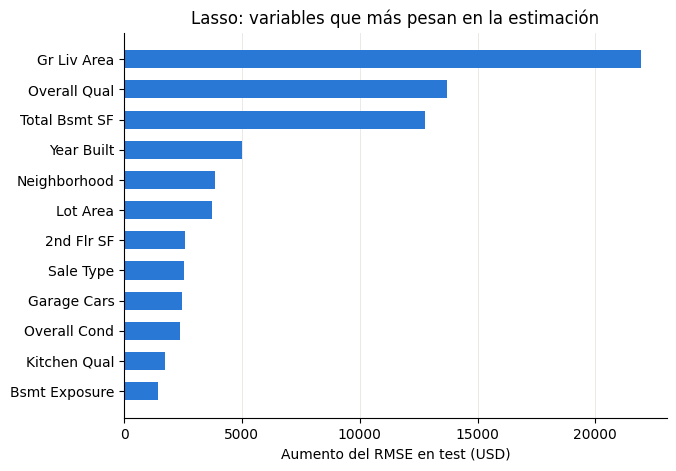

In [15]:
def importancia_por_variable(modelo, X, y, repeticiones=10):
    # Importancia por permutación agrupando las dummies de cada variable original:
    # cuánto sube el RMSE (USD) si se desordena esa variable.
    grupos = {}
    for col in X.columns:
        grupo = col if col.startswith('Tiene_') else col.split('_')[0]
        grupos.setdefault(grupo, []).append(col)
    base = root_mean_squared_error(y, modelo.predict(X))
    rng = np.random.default_rng(RANDOM_STATE)
    resultado = {}
    for grupo, cols in grupos.items():
        aumentos = []
        for _ in range(repeticiones):
            X_perm = X.copy()
            X_perm[cols] = X[cols].values[rng.permutation(len(X))]
            aumentos.append(root_mean_squared_error(y, modelo.predict(X_perm)) - base)
        resultado[grupo] = np.mean(aumentos)
    return pd.Series(resultado).sort_values(ascending=False)


X_te_elegido = datos[modelos[elegido][0]]['test'][0]
importancia = importancia_por_variable(ajustados[elegido], X_te_elegido, real)
print("Aumento del RMSE en test al desordenar cada variable (USD):")
print(importancia.head(15).round(0).to_string())

top = importancia.head(12)[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.values, color=COLOR, height=0.6)
ax.set(xlabel='Aumento del RMSE en test (USD)', title=f'{elegido}: variables que más pesan en la estimación')
ax.grid(axis='y', visible=False)
plt.show()

La importancia por permutación mide cuánto empeora el RMSE en test si se desordena una variable; las dummies de una misma variable se desordenan juntas. La superficie habitable (`Gr Liv Area`) es la que más pesa: sin ella, el RMSE sube unos 21.900 USD. Le siguen la calidad general (`Overall Qual`, 13.700 USD) y la superficie del sótano (`Total Bsmt SF`, 12.800 USD). Después vienen el año de construcción, el barrio y la superficie del terreno, con entre 3.700 y 5.000 USD. Son tamaño, calidad, antigüedad y ubicación, los mismos factores que considera cualquier tasación.

`Sale Type` aparece en el octavo lugar: el modelo usa el tipo de venta, y por eso al tasar una casa se le asigna `WD`, una venta normal (sección 11 del notebook de preparación).

In [16]:
# Desglose de una estimación (solo aplica a un modelo lineal). En escala log el modelo lineal es una suma, así que la estimación se puede
# separar en el aporte de cada variable respecto de una casa con los valores promedio de train.
X_tr_elegido = datos[modelos[elegido][0]]['train'][0]
regresor = ajustados[elegido].regressor_
base_log = regresor.intercept_ + X_tr_elegido.mean().values @ regresor.coef_

ejemplo = (real - real.median()).abs().idxmin()   # la casa de test con el precio más cercano a la mediana
aportes = (X_te_elegido.loc[ejemplo] - X_tr_elegido.mean()) * regresor.coef_
aportes = aportes.groupby(lambda c: c if c.startswith('Tiene_') else c.split('_')[0]).sum()
principales = aportes.reindex(aportes.abs().sort_values(ascending=False).index).head(6)
principales['Resto de variables'] = aportes.sum() - principales.sum()

print(f"Casa id {ejemplo} ({seg_test.loc[ejemplo, 'Neighborhood']}): precio real {real[ejemplo]:,.0f} USD")
print(f"Punto de partida (casa con valores promedio): {np.expm1(base_log):,.0f} USD")
for variable, aporte in principales.items():
    print(f"  {variable:22s} {np.expm1(aporte) * 100:+6.1f} %")
estimado = np.expm1(base_log + aportes.sum())
print(f"Estimación: {estimado:,.0f} USD (modelo: {pred[ejemplo]:,.0f} USD)")

Casa id 1606 (Mitchel): precio real 160,000 USD
Punto de partida (casa con valores promedio): 167,304 USD
  Functional               -7.9 %
  Gr Liv Area              +8.3 %
  Overall Cond             +6.2 %
  Year Built               -4.6 %
  2nd Flr SF               +3.5 %
  Lot Area                 +2.6 %
  Resto de variables       -1.0 %
Estimación: 177,830 USD (modelo: 177,830 USD)


Como el modelo es lineal en la escala logarítmica, cada estimación se puede separar en el aporte de cada variable. El punto de partida es una casa con los valores promedio de train (167.304 USD), y cada variable sube o baja ese valor en un porcentaje. En la casa del ejemplo (id 1606, en `Mitchel`, vendida en 160.000 USD), la superficie habitable suma 8,3 % y la condición general 6,2 %, mientras que la funcionalidad (`Functional`) resta 7,9 % y el año de construcción 4,6 %. El modelo estima 177.830 USD, un 11 % sobre el precio real.

Este desglose permite justificar un valor ante un cliente o un banco: el perito ve qué variables movieron la estimación y puede revisar si alguna está mal registrada. En Random Forest y XGBoost no hay una descomposición directa como esta; habría que calcularla con herramientas adicionales, como SHAP.

In [17]:
# ¿Rinde peor el modelo en los barrios con pocas ventas? (EP1, sesgo de representación: menos de 30 casas)
casas_por_barrio = segmentos['Neighborhood'].value_counts()
poco_representado = seg_test['Neighborhood'].map(casas_por_barrio) < 30
print(f"Barrios con menos de 30 casas en los datos: {sorted(casas_por_barrio[casas_por_barrio < 30].index)}")
print(pd.DataFrame({'Casas en test': poco_representado.value_counts(),
                    'MAPE %': error_pct.groupby(poco_representado).mean().round(1)})
      .rename(index={True: 'Barrio con menos de 30 casas', False: 'Resto'}).to_string())

Barrios con menos de 30 casas en los datos: ['Blmngtn', 'Blueste', 'Greens', 'GrnHill', 'Landmrk', 'NPkVill', 'Veenker']
                              Casas en test  MAPE %
Neighborhood                                       
Resto                                   565     6.8
Barrio con menos de 30 casas             17     4.7


La EP1 propuso derivar a tasación manual las casas de los barrios con menos de 30 ventas, porque el modelo tiene pocos ejemplos de ellos. En este test no aparece ese problema: las 17 casas de esos barrios tienen un MAPE de 4,7 %, menor que el 6,8 % del resto. Son pocas casas para concluir que el modelo funciona bien ahí, así que la regla de la EP1 se puede mantener como precaución, pero estos datos no la exigen.

## 9. Conclusiones

El modelo elegido es Lasso. Es uno de los dos modelos que cumplen el criterio de salida completo de la EP1 en el test, y entre esos dos es el que usa menos variables, con la misma precisión que Ridge.

| KPI | Umbral | Lasso, test real | Lasso, venta normal impuesta |
|---|---|---|---|
| R² | ≥ 0,85 | 0,948 | 0,949 |
| RMSE | ≤ 30.000 USD | 19.241 USD | 19.084 USD |
| MAE | ≤ 20.000 USD | 12.407 USD | 12.462 USD |
| MAPE | ≤ 12 % | 6,77 % | 6,93 % |
| Brecha de R² entre train y test | ≤ 5 puntos | −0,9 | −1,0 |
| Brecha de MAPE entre barrios | ≤ 8 puntos | 6,1 | 6,2 |

Por qué Lasso y no los otros modelos:

- Frente a Random Forest y XGBoost, se equivoca menos (unos 4.000 y 2.400 USD menos de RMSE en test) y no sobreajusta. Con sus parámetros iniciales, los árboles casi memorizan train y no cumplen la brecha de R²; Random Forest tampoco cumple la de equidad.
- Frente a Ridge, tiene la misma precisión (115 USD de diferencia de RMSE en test) con 33 columnas menos.
- Cada estimación se descompone en el aporte de cada variable. Eso responde a la necesidad de trazabilidad del problema de negocio: el valor se puede justificar y revisar.

Uso recomendado: valor de partida para el perito en viviendas de zonas residenciales, tasadas como venta normal y con `Yr Sold = 2010`. En el test, la mitad de las casas tuvo un error menor a 5,3 % y casi 8 de cada 10 uno menor a 10 %.

Limitaciones:

- Subestima las casas de más de 450.000 USD y sobreestima algo las del cuartil más barato. En esos extremos el perito debería revisar el valor con más cuidado.
- En las ventas anómalas o entre familiares el error es de 11 % a 15 %, y esas ventas no se pueden identificar antes de vender.
- Las zonas no residenciales quedan fuera del alcance y van a tasación manual.
- Los datos son de 2006 a 2010: el modelo tasa a precios de ese período.

Queda para la búsqueda de hiperparámetros ver si Random Forest y XGBoost cumplen la brecha de R² al limitar la profundidad de los árboles.